# Quantum Chemistry Part 2

NicDeclic  
2026-10-14

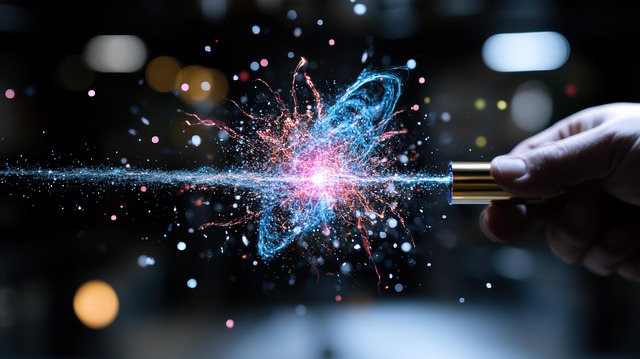

> *“Your only adversary is the mirror that refuses to reflect all your
> colors.”*  
> — **Professor Alvin**

------------------------------------------------------------------------

[![](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/nicdeclic/quantum-molecular-computing/blob/main/posts/quantum-chemistry/index.ipynb)

In [1]:
import sys
if 'google.colab' in sys.modules:
    # 1. Download qmc.py from GitHub
    !wget -q https://raw.githubusercontent.com/nicdeclic/quantum-molecular-computing/main/qmc.py
    
    # 2. Download requirements.txt from GitHub
    !wget -q https://raw.githubusercontent.com/nicdeclic/quantum-molecular-computing/main/requirements.txt

    # 3. Install dependencies
    !pip install -q -r requirements.txt

sys.path.insert(0, "../../src") # Select root directory
from qmc import * # QMC library

%reload_ext autoreload
%autoreload 2

------------------------------------------------------------------------

## Solving the Rigidity Deadlock

Let us now step back and examine molecules in their complete,
**closed-form** topologies—where every single carbon atom of the network
is explicitly accounted for, with no dangling bonds or hidden external
leads.

Consider the resonance manifold of a relatively simple structure: the
**Double Honeycomb** (naphthalene-like fused rings).

``` python
# Create a conjugated carbon molecule
mol1 = CarbonMolecule("Double Honeycomb")

# Add atoms
c1_1 = mol1.add_atom(x=-0.25, y=1)
c1_2 = mol1.add_atom(x=0.25, y=1)
c1_3 = mol1.add_atom(x=-0.5, y=0.5)
c1_4 = mol1.add_atom(x=0.5, y=0.5)
c1_5 = mol1.add_atom(x=-0.25, y=0)
c1_6 = mol1.add_atom(x=0.25, y=0)
c1_7 = mol1.add_atom(x=-0.5, y=-0.5)
c1_8 = mol1.add_atom(x=0.5, y=-0.5)
c1_9 = mol1.add_atom(x=-0.25, y=-1)
c1_10 = mol1.add_atom(x=0.25, y=-1)

# Add bonds
b1_1 = mol1.add_bond(c1_1, c1_2, order="single", label="A", role="input")
b1_2 = mol1.add_bond(c1_2, c1_4, order="single")
b1_3 = mol1.add_bond(c1_1, c1_3, order="single")
b1_4 = mol1.add_bond(c1_3, c1_5, order="single")
b1_5 = mol1.add_bond(c1_4, c1_6, order="single")
b1_6 = mol1.add_bond(c1_5, c1_6, order="single")
b1_7 = mol1.add_bond(c1_5, c1_7, order="single")
b1_8 = mol1.add_bond(c1_6, c1_8, order="single")
b1_9 = mol1.add_bond(c1_7, c1_9, order="single")
b1_10 = mol1.add_bond(c1_8, c1_10, order="single")
b1_11 = mol1.add_bond(c1_9, c1_10, order="single", label="B", role="output")

all_resonances = mol1.resonance()

for i, res_mol in enumerate(all_resonances):
    res_mol.draw() 
```

<table style="width:100%;">
<colgroup>
<col style="width: 33%" />
<col style="width: 33%" />
<col style="width: 33%" />
</colgroup>
<tbody>
<tr>
<td style="text-align: center;"><div width="33.3%"
data-layout-align="center">
<p>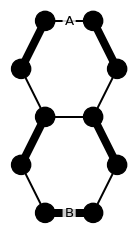</p>
</div></td>
<td style="text-align: center;"><div width="33.3%"
data-layout-align="center">
<p>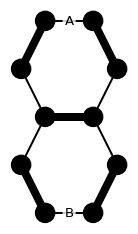</p>
</div></td>
<td style="text-align: center;"><div width="33.3%"
data-layout-align="center">
<p>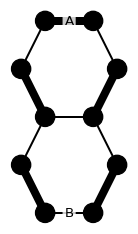</p>
</div></td>
</tr>
</tbody>
</table>

Now, let us isolate and observe the resulting resonance truth table
strictly across boundary bonds $A$ and $B$:

``` python
CarbonMolecule.resonance_table(all_resonances)
```

<table>
<colgroup>
<col style="width: 100%" />
</colgroup>
<tbody>
<tr>
<td style="text-align: left;"><div width="100.0%"
data-layout-align="left">
<p><span class="math display">$$\begin{array}{|c|c|} \hline \mathbf{A}
&amp; \mathbf{B} \\ \hline 0 &amp; 1 \\ 0 &amp; 0 \\ 1 &amp; 0 \\ \hline
\end{array}$$</span></p>
</div></td>
</tr>
</tbody>
</table>

Designating bond $A$ as an **input** and bond $B$ as an **output**
reveals something remarkable:

When input $A$ is held at state **“0”** (single bond), output $B$ is no
longer clamped to a single, rigid outcome. Instead, it can naturally
manifest in **two distinct states: “0” or “1”**.

This is an immensely encouraging breakthrough. This internal branching
is precisely the missing degree of freedom that eluded us when analyzing
isolated junctions!

And this is by no means an isolated anomaly. The overwhelming majority
of closed-form conjugated networks exhibit this rich internal
multiplicity. All it took was shifting the perspective: **stepping back
to appreciate the entire molecular forest rather than obsessing over an
isolated junction tree.**

However, this breakthrough carries a profound theoretical consequence:
**deterministic certainty dissolves here.**

Because a single input state maps to multiple admissible physical
configurations, classical boolean determinism can no longer describe the
computation. We are inevitably forced to expand our mathematical
framework into the domain of **statistics**.

------------------------------------------------------------------------

## Probabilistic Bits (p-bits)

Probabilistic bits provide a robust mathematical framework for encoding
and processing information. By applying this formalism to carbon-carbon
bonds, we can natively capture the stochastic nature of chemical systems
and open up new frontiers in molecular computing.

Think of a coin toss. Once flipped, the coin can land on tails (state
**“0”**) or heads (state **“1”**).

With a fair coin, there is an equal probability — a 50% chance—of
landing on state “0” and a 50% chance of landing on state “1”.

Mathematically, we formulate probabilistic bits using the same
transition matrices introduced earlier. The only operational difference
lies in the continuous values of the matrix elements rather than
discrete binary indicators.

- **A fair coin:**

In [4]:
display_inline("Fair", "=", random.to_katex(show_labels=True))

The first element quantifies the probability of observing a **“0”**; the
second element quantifies the probability of observing a **“1”**.

We could also bias the coin so that it carries a one-in-four chance
(25%) of landing on “0”, and a three-in-four chance (75%) of landing on
“1”.

- **A biased coin:**

In [5]:
biased = TransitionMatrix([
    [0.25, 0.75]
])

display_inline("Biased", "=", biased.to_katex(show_labels=True))

The limiting boundary case occurs when there is a 0% chance of being in
one state and a 100% chance of being in the other. Under these
conditions, deterministic certainty is recovered, and the probabilistic
bit collapses back into a classical boolean bit ($[1, 0]$ or $[0, 1]$).

Any transition matrix is physically and computationally admissible in
our model if it satisfies three structural properties:

1.  **Bounded Probabilities:** Every individual element must lie
    strictly within the closed interval $[0, 1]$ (no negative or
    super-unitary probabilities).  
2.  **Conservation of Probability:** For any accessible state, the
    elements along the row must sum to **exactly 1** (100% of the
    probability distribution, ensuring no leakage into unmodeled
    states).  
3.  **Forbidden Inputs:** If an input configuration is topologically or
    chemically forbidden by the molecular network, all elements along
    that row sum to **exactly 0**, acting as an algebraic filter that
    rejects unphysical states.

------------------------------------------------------------------------

We can now derive the complete transition matrix for the Double
Honeycomb molecule (with bond 𝐴 as an input and bond 𝐵 as an output):

``` python
doubleHoneycomb = TransitionMatrix.from_resonances(all_resonances)

display_inline("DoubleHoneycomb", "=", doubleHoneycomb.to_katex(show_labels=True))
```

<table>
<colgroup>
<col style="width: 100%" />
</colgroup>
<tbody>
<tr>
<td style="text-align: left;"><div width="100.0%"
data-layout-align="left">
<p><span class="math display">$$ DoubleHoneycomb =  \begin{array}{r|cc|}
\text{} &amp; \text{``0''} &amp; \text{``1''} \\  \hline \text{``0''}
&amp; 0.5 &amp; 0.5 \\ \text{``1''} &amp; 1 &amp; 0 \\  \hline
\end{array}  $$</span></p>
</div></td>
</tr>
</tbody>
</table>

Examining the matrix reveals an interesting hybrid behavior:  
\* When input $A$ is held at **“0”**, output $B$ behaves as a **fair
coin** ($[0.5 \quad 0.5]$), exhibiting true probabilistic branching.  
\* When input $A$ is held at **“1”**, output $B$ collapses into a
**deterministic boolean bit** strictly clamped to **“0”**
($[1.0 \quad 0.0]$).

------------------------------------------------------------------------

## Solving the Universal Logic Deadlock

At first glance, one might worry that all these fractional probability
matrices are merely drifting further away from our original goal:
constructing deterministic, universal logic gates.

Intuitively, however, a compelling hypothesis emerges: **what happens if
we mirror and fuse two identical junctions together?**

Because both halves share identical resonance tables, connecting their
boundaries should not induce chaotic frustration or instability.
Instead, mutual geometric symmetry could act as an internal stabilizer,
potentially maintaining deterministic transitions. It was by no means
guaranteed, but it was an avenue demanding exploration.

This hunch led to an astonishing breakthrough when fusing **two
triangular junctions** face-to-face.

``` python
# Create a conjugated carbon molecule
mol = CarbonMolecule("2X Triangular Junction")

# Add atoms
c2_1 = mol.add_atom(x=-0.8, y=0.5)
c2_2 = mol.add_atom(x=0.3, y=0.5, visible=False)
c2_3 = mol.add_atom(x=-0.8, y=-0.5)
c2_4 = mol.add_atom(x=0.3, y=-0.5, visible=False)
c2_5 = mol.add_atom(x=-0.3, y=0)
c2_6 = mol.add_atom(x=0.3, y=0, visible=False)

c2_7 = mol.add_atom(x=1.8, y=0.5)
c2_8 = mol.add_atom(x=0.7, y=0.5, visible=False)
c2_9 = mol.add_atom(x=1.8, y=-0.5)
c2_10 = mol.add_atom(x=0.7, y=-0.5, visible=False)
c2_11 = mol.add_atom(x=1.3, y=0)
c2_12 = mol.add_atom(x=0.7, y=0, visible=False)


# Add bonds
b2_1 = mol.add_bond(c2_1, c2_2, order="single", label="A")
b2_2 = mol.add_bond(c2_3, c2_4, order="single", label="B")
b2_3 = mol.add_bond(c2_5, c2_6, order="single", label="C")
b2_4 = mol.add_bond(c2_1, c2_3, order="single", label="E1")
b2_5 = mol.add_bond(c2_3, c2_5, order="single", label="F1")
b2_6 = mol.add_bond(c2_5, c2_1, order="single", label="D1")

b2_7 = mol.add_bond(c2_7, c2_8, order="single", label="A")
b2_8 = mol.add_bond(c2_9, c2_10, order="single", label="B")
b2_9 = mol.add_bond(c2_11, c2_12, order="single", label="C")
b2_10 = mol.add_bond(c2_7, c2_9, order="single", label="E2")
b2_11 = mol.add_bond(c2_9, c2_11, order="single", label="F2")
b2_12 = mol.add_bond(c2_11, c2_7, order="single", label="D2")

# Draw with Schemdraw
mol.draw()
```

<table>
<colgroup>
<col style="width: 100%" />
</colgroup>
<tbody>
<tr>
<td style="text-align: center;"><div width="100.0%"
data-layout-align="center">
<p>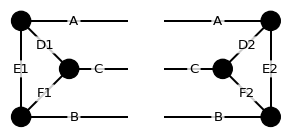</p>
</div></td>
</tr>
</tbody>
</table>

The resulting network forms a symmetric structure called the **“Letter
Envelope”**. Here are its 4 fundamental resonance structures:

``` python
# Create a conjugated carbon molecule
mol = CarbonMolecule("Letter Envelope")

# Add atoms
c2_1 = mol.add_atom(x=-0.8, y=0.5)
c2_2 = mol.add_atom(x=0.8, y=0.5)
c2_3 = mol.add_atom(x=-0.3, y=0)
c2_4 = mol.add_atom(x=0.3, y=0)
c2_5 = mol.add_atom(x=-0.8, y=-0.5)
c2_6 = mol.add_atom(x=0.8, y=-0.5)

# Add bonds
b2_1 = mol.add_bond(c2_1, c2_2, order="single", label="A")
b2_2 = mol.add_bond(c2_1, c2_5, order="single", label="E1")
b2_3 = mol.add_bond(c2_2, c2_6, order="single", label="E2")
b2_4 = mol.add_bond(c2_1, c2_3, order="single", label="D1")
b2_5 = mol.add_bond(c2_2, c2_4, order="single", label="D2")
b2_6 = mol.add_bond(c2_3, c2_4, order="single", label="C")
b2_7 = mol.add_bond(c2_3, c2_5, order="single", label="F1")
b2_8 = mol.add_bond(c2_4, c2_6, order="single", label="F2")
b2_9 = mol.add_bond(c2_5, c2_6, order="single", label="B")

all_resonances = mol.resonance()

for i, res_mol in enumerate(all_resonances):
    res_mol.draw() 
```

<table>
<colgroup>
<col style="width: 100%" />
</colgroup>
<tbody>
<tr>
<td style="text-align: center;"><div width="100.0%"
data-layout-align="center">
<p>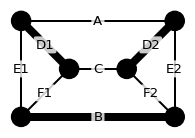</p>
</div></td>
</tr>
</tbody>
</table>

<table>
<colgroup>
<col style="width: 100%" />
</colgroup>
<tbody>
<tr>
<td style="text-align: center;"><div width="100.0%"
data-layout-align="center">
<p>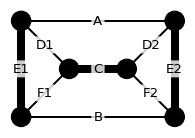</p>
</div></td>
</tr>
</tbody>
</table>

<table>
<colgroup>
<col style="width: 100%" />
</colgroup>
<tbody>
<tr>
<td style="text-align: center;"><div width="100.0%"
data-layout-align="center">
<p>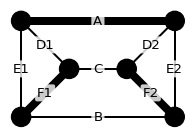</p>
</div></td>
</tr>
</tbody>
</table>

<table>
<colgroup>
<col style="width: 100%" />
</colgroup>
<tbody>
<tr>
<td style="text-align: center;"><div width="100.0%"
data-layout-align="center">
<p>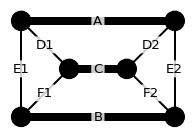</p>
</div></td>
</tr>
</tbody>
</table>

Now, let us examine the global resonance table across all labeled bonds:

``` python
CarbonMolecule.resonance_table(all_resonances)
```

<table>
<colgroup>
<col style="width: 100%" />
</colgroup>
<tbody>
<tr>
<td style="text-align: left;"><div width="100.0%"
data-layout-align="left">
<p><span class="math display">$$\begin{array}{|c|c|c|c|c|c|c|c|c|}
\hline \mathbf{A} &amp; \mathbf{B} &amp; \mathbf{C} &amp; \mathbf{D1}
&amp; \mathbf{D2} &amp; \mathbf{E1} &amp; \mathbf{E2} &amp; \mathbf{F1}
&amp; \mathbf{F2} \\ \hline 0 &amp; 1 &amp; 0 &amp; 1 &amp; 1 &amp; 0
&amp; 0 &amp; 0 &amp; 0 \\ 0 &amp; 0 &amp; 1 &amp; 0 &amp; 0 &amp; 1
&amp; 1 &amp; 0 &amp; 0 \\ 1 &amp; 0 &amp; 0 &amp; 0 &amp; 0 &amp; 0
&amp; 0 &amp; 1 &amp; 1 \\ 1 &amp; 1 &amp; 1 &amp; 0 &amp; 0 &amp; 0
&amp; 0 &amp; 0 &amp; 0 \\ \hline \end{array}$$</span></p>
</div></td>
</tr>
</tbody>
</table>

If we assign **$A$ and $B$ as inputs** and inspect bond **$C$ as the
output**, we recover our familiar **XNOR gate**. Given that both halves
are triangular junctions, this is reassuring, but not groundbreaking.

**Now, shift your focus to bond $E1$ instead.**

Look at the truth table for $E1$:  
\* $E1$ evaluates to **“1”** *if and only if* both inputs $A$ and $B$
are **“0”**.  
\* In all other configurations, $E1$ evaluates strictly to **“0”**.

This is the exact, canonical definition of a **NOR gate** !

Not only is the NOR gate a **universal logic primitive** capable of
synthesizing any classical computational function (NAND, AND, OR, XOR),
but this molecular geometry natively provides **two symmetric outputs
for the price of one** ($E1$ and $E2$ yield identical values, offering
built-in fan-out).

The universal logic deadlock is officially broken. We now possess a
tangible molecular blueprint for universal boolean computation etched
directly into a conjugated carbon skeleton.

------------------------------------------------------------------------

## Dual-Rail Interconnects

Now that we have successfully synthesized a universal NOR gate within a
closed-form molecule, a critical architectural question emerges: **how
do we chain these logic gates together to build complex circuits?**

The naive approach—connecting functional blocks via a single, isolated
carbon bond as we did with elementary junctions—is no longer viable.

Examine what happens when we open one of the inputs of our “Letter
Envelope” molecule: it does not terminate in a single dangling bond, but
rather in a **symmetric pair of coupled branches**. Due to the internal
geometry of the resonance network, these two parallel branches are
physically locked together—they will **always carry the exact same
logical state** simultaneously.

``` python
# Create a conjugated carbon molecule
mol = CarbonMolecule("Letter Envelope")

# Add atoms
c_1a = mol.add_atom(x=-0.8, y=0.5)
c_1b = mol.add_atom(x=-0.4, y=0.7, visible=False)
c_2a = mol.add_atom(x=0.8, y=0.5)
c_2b = mol.add_atom(x=0.4, y=0.7, visible=False)
c_3 = mol.add_atom(x=-0.3, y=0)
c_4 = mol.add_atom(x=0.3, y=0)
c_5 = mol.add_atom(x=-0.8, y=-0.5)
c_6 = mol.add_atom(x=0.8, y=-0.5)

# Add bonds
b_1a = mol.add_bond(c_1a, c_1b, order="single")
b_1b = mol.add_bond(c_2a, c_2b, order="single")
b_2 = mol.add_bond(c_1a, c_5, order="single")
b_3 = mol.add_bond(c_2a, c_6, order="single")
b_4 = mol.add_bond(c_1a, c_3, order="single")
b_5 = mol.add_bond(c_2a, c_4, order="single")
b_6 = mol.add_bond(c_3, c_4, order="single")
b_7 = mol.add_bond(c_3, c_5, order="single")
b_8 = mol.add_bond(c_4, c_6, order="single")
b_9 = mol.add_bond(c_5, c_6, order="single")

all_resonances = mol.resonance()

for i, res_mol in enumerate(all_resonances):
    res_mol.draw() 
```

<table>
<colgroup>
<col style="width: 50%" />
<col style="width: 50%" />
</colgroup>
<tbody>
<tr>
<td style="text-align: center;"><div width="50.0%"
data-layout-align="center">
<p>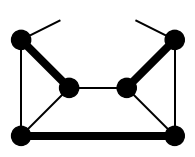</p>
</div></td>
<td style="text-align: center;"><div width="50.0%"
data-layout-align="center">
<p>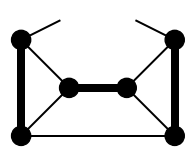</p>
</div></td>
</tr>
</tbody>
</table>

<table>
<colgroup>
<col style="width: 50%" />
<col style="width: 50%" />
</colgroup>
<tbody>
<tr>
<td style="text-align: center;"><div width="50.0%"
data-layout-align="center">
<p>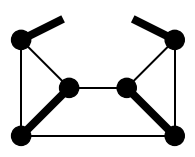</p>
</div></td>
<td style="text-align: center;"><div width="50.0%"
data-layout-align="center">
<p>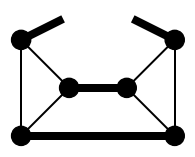</p>
</div></td>
</tr>
</tbody>
</table>

The engineering solution is as elegant as it is direct: **instead of
routing a single line, we route both branches in parallel.**

Suppose we want to connect the input ‘A’ to two XNOR gates:

``` python
with schemdraw.Drawing() as d:
    d.config(fontsize=12, unit=2.5)

    # 1. Top XNOR gate (Inputs: A, B -> Output: D)
    top_gate = d.add(logic.Xnor().right().label("XNOR 1", loc="top"))
    
    # Lead wire and label for Input B (top pin of top gate)
    d.add(elm.Line().left(2.5).at(top_gate.in1).label("B", loc="left"))
    
    # Output wire and label for Output D
    d.add(elm.Line().right(1.5).at(top_gate.out).label("D", loc="right"))

    # 2. Bottom XNOR gate (Inputs: A, C -> Output: E)
    # Positioned neatly below the first gate
    bottom_gate = d.add(
        logic.Xnor().right().at((top_gate.absanchors["in1"][0], top_gate.absanchors["in1"][1] - 3.5))
        .label("XNOR 2", loc="bottom")
    )

    # Lead wire and label for Input C (bottom pin of bottom gate)
    d.add(elm.Line().left(2.5).at(bottom_gate.in2).label("C", loc="left"))
    
    # Output wire and label for Output E
    d.add(elm.Line().right(1.5).at(bottom_gate.out).label("E", loc="right"))

    # 3. Shared Input A routing (Fan-out to top_gate.in2 and bottom_gate.in1)
    # Lead line from the left
    mid_y = (top_gate.in2[1] + bottom_gate.in1[1]) / 2.0
    input_A = d.add(elm.Line().right(1.2).at((top_gate.in1[0] - 2.5, mid_y)).label("A", loc="left"))
    
    # Route branch up into top gate (in2)
    d.add(elm.Wire("-|").at(input_A.end).to(top_gate.in2))

    # Route branch down into bottom gate (in1)
    d.add(elm.Wire("-|").at(input_A.end).to(bottom_gate.in1))
```

<table>
<colgroup>
<col style="width: 100%" />
</colgroup>
<tbody>
<tr>
<td style="text-align: left;"><div width="100.0%"
data-layout-align="left">
<figure>

<figcaption aria-hidden="true">Logic Circuit</figcaption>
</figure>
</div></td>
</tr>
</tbody>
</table>

This will be the resulting molecule:

``` python
# Create a conjugated carbon molecule
mol = CarbonMolecule("Connected Letter Envelopes")

# Add atoms
c1_1 = mol.add_atom(x=-0.8, y=0.5)
c1_2 = mol.add_atom(x=0.8, y=0.5)
c1_3 = mol.add_atom(x=-0.3, y=0)
c1_4 = mol.add_atom(x=0.3, y=0)
c1_5 = mol.add_atom(x=-0.8, y=-0.5)
c1_6 = mol.add_atom(x=0.8, y=-0.5)

c2_1 = mol.add_atom(x=1.8, y=0.5)
c2_2 = mol.add_atom(x=3.4, y=0.5)
c2_3 = mol.add_atom(x=2.3, y=0)
c2_4 = mol.add_atom(x=2.9, y=0)
c2_5 = mol.add_atom(x=1.8, y=-0.5)
c2_6 = mol.add_atom(x=3.4, y=-0.5)

c3_1 = mol.add_atom(x=-0.8, y=1.2)
c3_2 = mol.add_atom(x=3.4, y=1.2)

# Add bonds
b1_2 = mol.add_bond(c1_1, c1_5, order="single")
b1_3 = mol.add_bond(c1_2, c1_6, order="single")
b1_4 = mol.add_bond(c1_1, c1_3, order="single")
b1_5 = mol.add_bond(c1_2, c1_4, order="single")
b1_6 = mol.add_bond(c1_3, c1_4, order="single", label="D")
b1_7 = mol.add_bond(c1_3, c1_5, order="single")
b1_8 = mol.add_bond(c1_4, c1_6, order="single")
b1_9 = mol.add_bond(c1_5, c1_6, order="single", label="B")

b2_2 = mol.add_bond(c2_1, c2_5, order="single")
b2_3 = mol.add_bond(c2_2, c2_6, order="single")
b2_4 = mol.add_bond(c2_1, c2_3, order="single")
b2_5 = mol.add_bond(c2_2, c2_4, order="single")
b2_6 = mol.add_bond(c2_3, c2_4, order="single", label="E")
b2_7 = mol.add_bond(c2_3, c2_5, order="single")
b2_8 = mol.add_bond(c2_4, c2_6, order="single")
b2_9 = mol.add_bond(c2_5, c2_6, order="single", label="C")

b3_1 = mol.add_bond(c1_1, c3_1, order="single")
b3_2 = mol.add_bond(c3_1, c3_2, order="single", label="A")
b3_3 = mol.add_bond(c3_2, c2_2, order="single")
b3_4 = mol.add_bond(c1_2, c2_1, order="single")

# Draw with Schemdraw
mol.draw()
```

<table>
<colgroup>
<col style="width: 100%" />
</colgroup>
<tbody>
<tr>
<td style="text-align: left;"><div width="100.0%"
data-layout-align="left">
<figure>
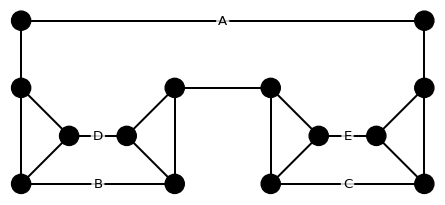
<figcaption aria-hidden="true">Equivalent Molecular Circuit</figcaption>
</figure>
</div></td>
</tr>
</tbody>
</table>

In modern computer architecture, this paradigm is well known as
**dual-rail logic** (or differential signaling). In our molecular
context, information is not propagated across a single wire, but through
a two-lane conjugated pathway.

Notice that the top branch incorporates two additional carbon atoms
compared to the bottom branch. This specific geometric offset is not
strictly mandatory: as long as we insert an **even number of carbon
atoms** along the conjugated pathway, the wire remains logically
equivalent and non-inverting (a pure identity interconnect).

Conversely, inserting an **odd number of carbon atoms** into each branch
introduces a parity shift in the alternating double/single bonds. This
naturally inverts the logical state, effectively transforming the
interconnect itself into a built-in **NOT gate** without requiring any
additional circuit components.

Furthermore, the upper branch was chosen to represent the value of A.
However, the lower branch would have been equally suitable; they always
have the same value anyway.

------------------------------------------------------------------------

## Cascading Parasitic Resonance (Molecular Epilepsy)

The path now seems crystal clear: with a universal NOR gate and
dual-rail interconnects, it is theoretically possible to chain together
as many logic gates as the architecture demands. The logic is universal,
mathematically sound, and geometrically elegant.

The foundation appears to be firmly laid. All that remains is to build
upward.

Yet, as the very first bricks are set into place, the entire structure
shakes violently and collapses to the ground.

What on earth just happened?

Observe any realistic digital circuit. Signals do not merely propagate
along a single, open pipeline. Functional processors are inherently
dense, intertwined networks featuring branching, reconverging paths, and
feedback loops.

Every time we fuse two carbon networks together, we do not simply create
an abstract connection: **we synthesize a single, larger
macro-molecule**

To construct a circuit of even modest complexity, one must inevitably:
**open and interconnect two separate bonds within the very same
molecule.**

And that is where the physics turns against us.

Opening a single bond is well-behaved: the dangling bonds remain
strictly synchronized, faithfully executing the truth table.

However, the moment we expose a **second** connection port on that same
molecular envelope, an insidious form of crosstalk emerges. The extended
boundary conditions crack open the state space, allowing **four rogue,
parasitic resonance modes** to settle into the manifold.

``` python
# Create a conjugated carbon molecule
mol = CarbonMolecule("Letter Envelope")

# Add atoms
c_1a = mol.add_atom(x=-0.8, y=0.5)
c_1b = mol.add_atom(x=-0.4, y=0.7, visible=False)
c_2a = mol.add_atom(x=0.8, y=0.5)
c_2b = mol.add_atom(x=0.4, y=0.7, visible=False)
c_3 = mol.add_atom(x=-0.3, y=0)
c_4 = mol.add_atom(x=0.3, y=0)
c_5a = mol.add_atom(x=-0.8, y=-0.5)
c_5b = mol.add_atom(x=-0.4, y=-0.7, visible=False)
c_6a = mol.add_atom(x=0.8, y=-0.5)
c_6b = mol.add_atom(x=0.4, y=-0.7, visible=False)

# Add bonds
b_1a = mol.add_bond(c_1a, c_1b, order="single")
b_1b = mol.add_bond(c_2a, c_2b, order="single")
b_2 = mol.add_bond(c_1a, c_5a, order="single")
b_3 = mol.add_bond(c_2a, c_6a, order="single")
b_4 = mol.add_bond(c_1a, c_3, order="single")
b_5 = mol.add_bond(c_2a, c_4, order="single")
b_6 = mol.add_bond(c_3, c_4, order="single")
b_7 = mol.add_bond(c_3, c_5a, order="single")
b_8 = mol.add_bond(c_4, c_6a, order="single")
b_9a = mol.add_bond(c_5a, c_5b, order="single")
b_9b = mol.add_bond(c_6a, c_6b, order="single")

all_resonances = mol.resonance()

for i, res_mol in enumerate(all_resonances):
    res_mol.draw() 
```

<table>
<colgroup>
<col style="width: 50%" />
<col style="width: 50%" />
</colgroup>
<tbody>
<tr>
<td style="text-align: left;"><div width="50.0%"
data-layout-align="left">
<figure>
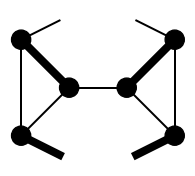
<figcaption aria-hidden="true">Valid State</figcaption>
</figure>
</div></td>
<td style="text-align: left;"><div width="50.0%"
data-layout-align="left">
<figure>
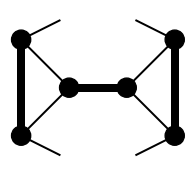
<figcaption aria-hidden="true">Valid State</figcaption>
</figure>
</div></td>
</tr>
</tbody>
</table>

<table>
<colgroup>
<col style="width: 50%" />
<col style="width: 50%" />
</colgroup>
<tbody>
<tr>
<td style="text-align: left;"><div width="50.0%"
data-layout-align="left">
<figure>
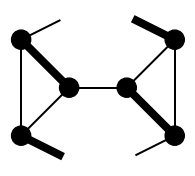
<figcaption aria-hidden="true">Unauthorized State</figcaption>
</figure>
</div></td>
<td style="text-align: left;"><div width="50.0%"
data-layout-align="left">
<figure>
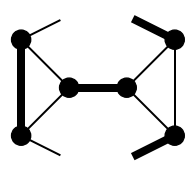
<figcaption aria-hidden="true">Unauthorized State</figcaption>
</figure>
</div></td>
</tr>
</tbody>
</table>

<table>
<colgroup>
<col style="width: 50%" />
<col style="width: 50%" />
</colgroup>
<tbody>
<tr>
<td style="text-align: left;"><div width="50.0%"
data-layout-align="left">
<figure>
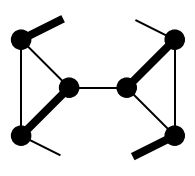
<figcaption aria-hidden="true">Unauthorized State</figcaption>
</figure>
</div></td>
<td style="text-align: left;"><div width="50.0%"
data-layout-align="left">
<figure>
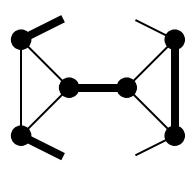
<figcaption aria-hidden="true">Unauthorized State</figcaption>
</figure>
</div></td>
</tr>
</tbody>
</table>

<table>
<colgroup>
<col style="width: 50%" />
<col style="width: 50%" />
</colgroup>
<tbody>
<tr>
<td style="text-align: left;"><div width="50.0%"
data-layout-align="left">
<figure>
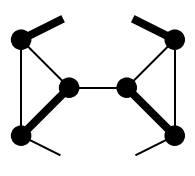
<figcaption aria-hidden="true">Valid State</figcaption>
</figure>
</div></td>
<td style="text-align: left;"><div width="50.0%"
data-layout-align="left">
<figure>
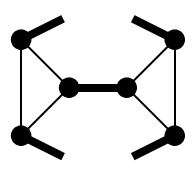
<figcaption aria-hidden="true">Valid State</figcaption>
</figure>
</div></td>
</tr>
</tbody>
</table>

After connecting the two open bonds together, two unauthorized states
will remain.

These two unauthorized states do not remain polite, isolated local
defects. Because the molecular $\pi$-system is continuous, these
parasitic modes propagate unimpeded throughout the entire network,
corrupting every gate in their path like a wildfire.

In formal physical terms, this catastrophic breakdown is known as
**Cascading Parasitic Resonance**.

A far more striking and visceral name for it, however, is **“Molecular
Epilepsy.”**

This is not a mere poetic metaphor. If one were to construct an
artificial neural network physically embodied in conjugated carbon
molecules, this is hypothetically the exact pathology that would emerge:
the moment an internal feedback loop loses its structural constraints, a
runaway parasitic resonance takes over the network, mimicking the
hypersynchronous seizure activity observed in biological neural tissue.

In other words, the machine ceases to calculate. It convulses.

------------------------------------------------------------------------

👉 **Next chapter :**  
**[“Quantum Chemistry Part
3”](../../posts/quantum-chemistry3/index.html)**